# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot
import spatialdata_plot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data_processed_filtered.zarr")
results = sdata["xrna_metadata"].var

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

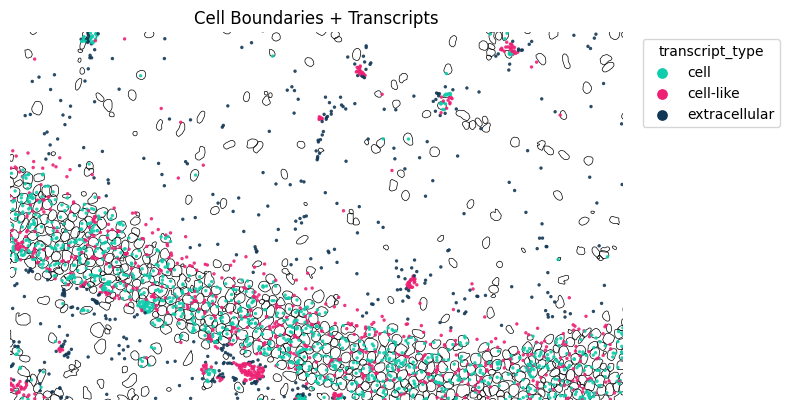

In [15]:
troutpy.pl.spatial_transcripts(
    sdata,
    gene_key="gene",
    gene_list=["Gad1"],
    colormap="30colors",
    color_key="transcript_type",
    scatter_size=6,
    boundary_linewidth=0.5,
    alpha=0.9,
    use_roi=True,
    roi=(4000, 4500, 4500, 4800),
    shapes_key="nucleus_boundaries",
)

### END OF THIS PART

In [3]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="total_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.001].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

# calculate modules
modules = hs.create_modules(min_gene_threshold=6, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

100%|██████████| 248/248 [00:01<00:00, 148.12it/s]


Computing pair-wise local correlation on 248 features...


100%|██████████| 30628/30628 [00:11<00:00, 2567.62it/s]


Computing scores for 18 modules...


100%|██████████| 18/18 [00:01<00:00, 13.23it/s]


In [ ]:
hs.plot_local_correlations(vmax=100, vmin=-100)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [30]:
dictmod = dict(zip(modules.index, modules.values))
results["module"] = results.index.map(dictmod)

In [31]:
results

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,...,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,ks_stat,ks_pval,ad_stat,lr_stat,mean_displacement,-log_ks_pval,module
Prox1,66159,3.998140,False,0.0,0.819299,0.180701,0.419068,0.309321,0.0,0.000003,...,0.639501,0.0,0.306969,0.108043,5.486568e-122,1267.728103,4697.702372,10.414344,279.213078,7
Bhlhe40,101785,4.428942,False,0.0,0.787356,0.212644,0.216522,0.072177,0.0,0.000003,...,0.313504,0.0,0.249292,0.282097,0.000000e+00,2468.152343,33845.697982,10.002110,690.775528,-1
Plcxd2,70270,4.058424,False,0.0,0.749950,0.250050,0.005809,0.271175,0.0,0.000003,...,0.613420,0.0,0.316309,0.250122,0.000000e+00,2252.888967,22304.042575,9.737339,690.775528,13
Fezf2,32622,3.291066,False,0.0,0.798326,0.201674,0.283329,0.156392,0.0,0.000003,...,0.516671,0.0,0.190621,0.242647,0.000000e+00,774.631313,6988.309931,10.405440,690.775528,8
Parm1,33673,3.322776,False,0.0,0.839070,0.160930,0.558786,0.115559,0.0,0.000003,...,0.343008,0.0,0.177583,0.210667,1.747351e-211,527.780604,4611.494044,10.100517,485.287354,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Arhgap25,12094,2.298789,False,0.0,0.806102,0.193898,0.332342,0.034138,0.0,0.000003,...,0.369277,0.0,0.069412,0.291127,1.553018e-176,166.750389,2929.206198,11.503975,404.814777,8
Shisa6,37334,3.425984,False,0.0,0.675095,0.324905,-0.361217,0.187418,0.0,0.000003,...,0.535325,0.0,0.225188,0.221968,0.000000e+00,1115.077391,14574.281068,14.170131,690.775528,11
Chat,3055,0.922859,False,0.0,0.856301,0.143699,0.692365,0.023036,0.0,0.000003,...,0.392573,0.0,0.038835,0.355641,3.436154e-50,27.527498,451.215704,22.944913,113.894902,5
Ano1,4704,1.354493,False,0.0,0.814626,0.185374,0.387815,0.028142,0.0,0.000003,...,0.352104,0.0,0.081864,0.343035,4.030503e-92,40.530167,1086.416066,15.475517,210.443937,5


In [7]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

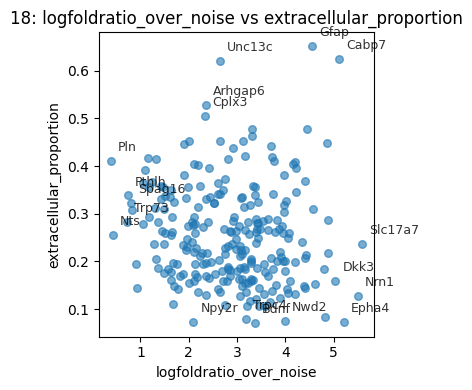

In [54]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

1


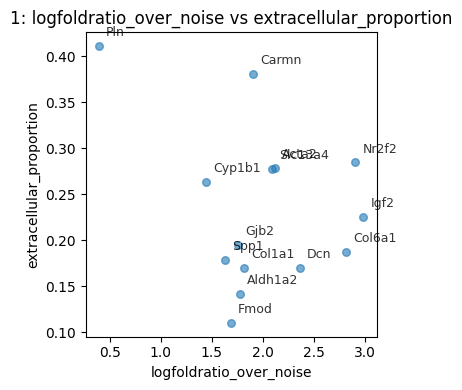

2


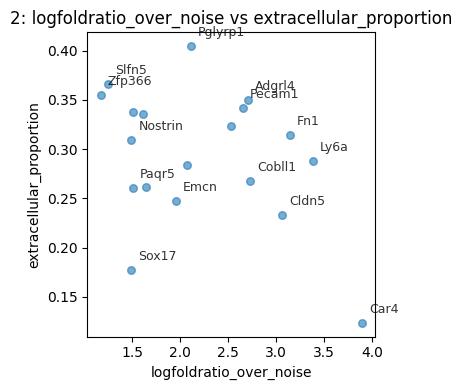

3


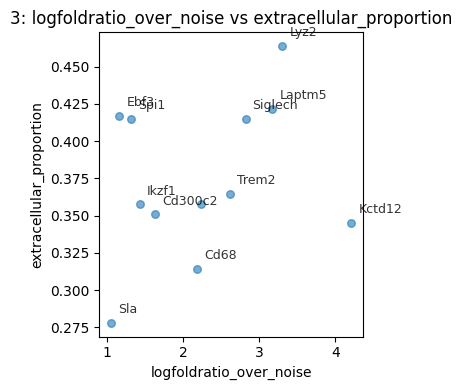

4


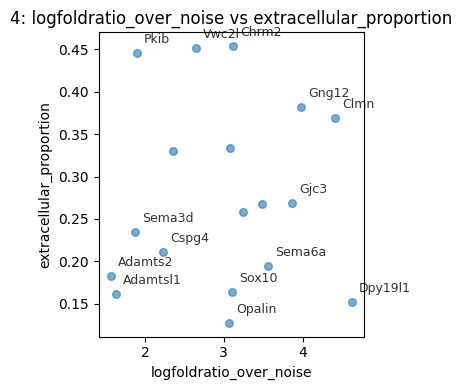

5


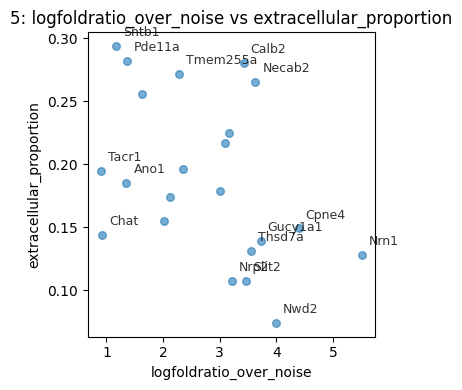

6


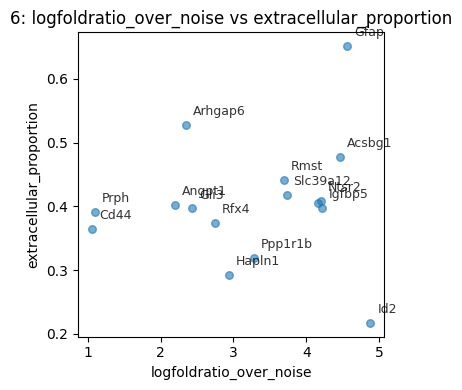

7


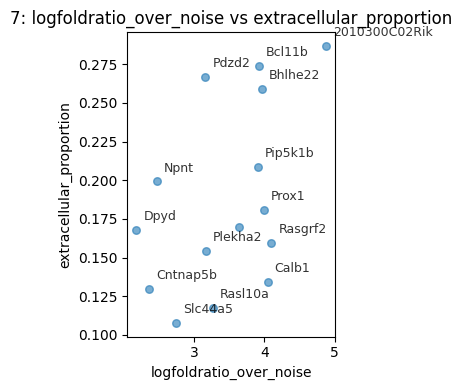

8


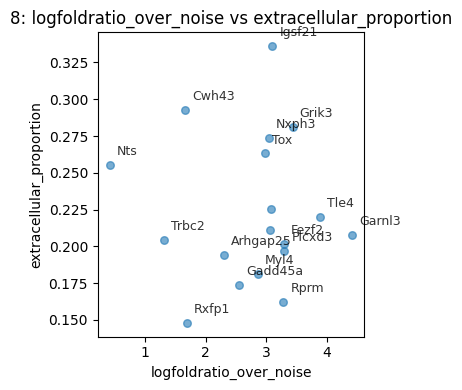

9


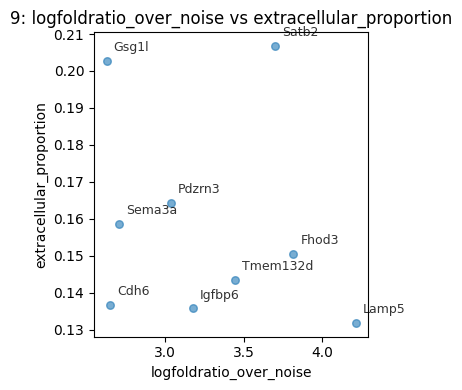

10


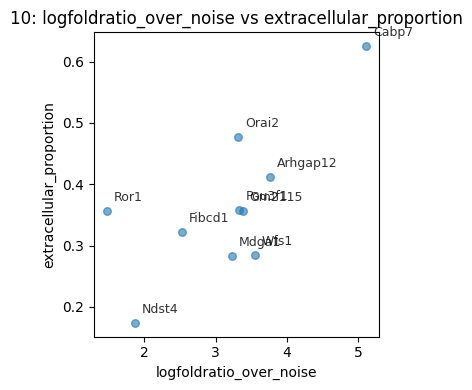

11


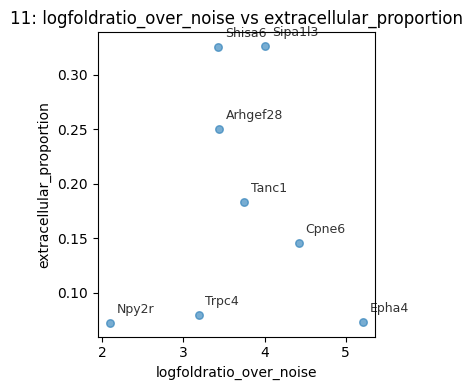

12


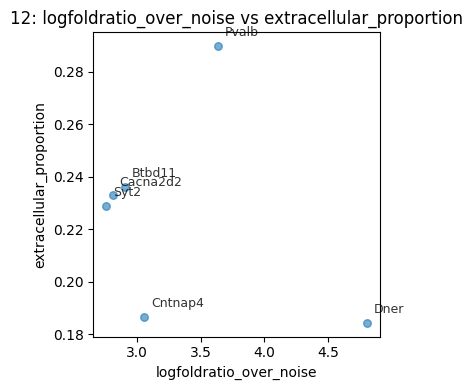

13


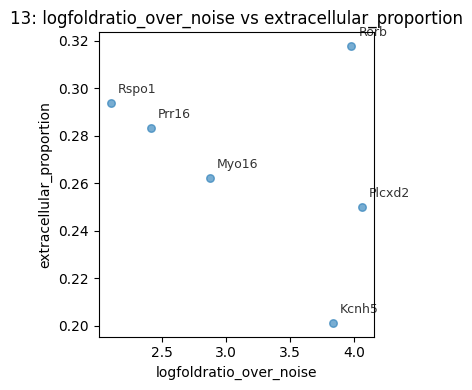

14


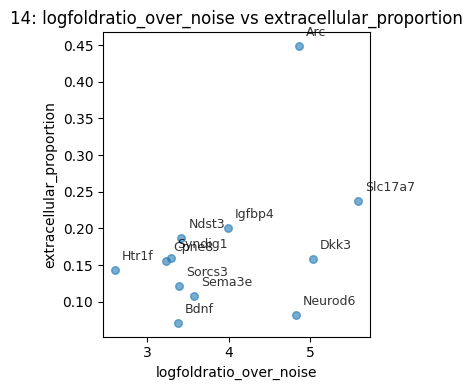

15


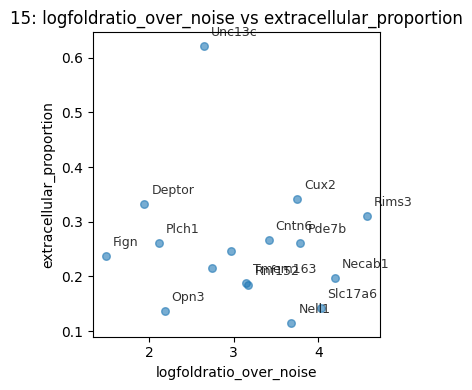

16


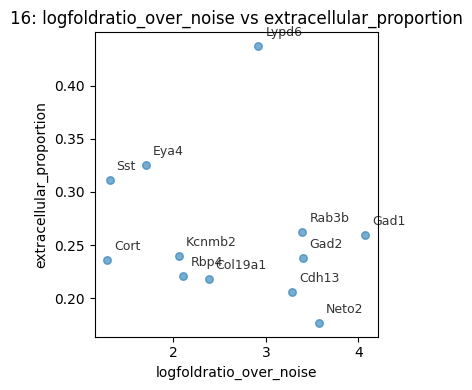

17


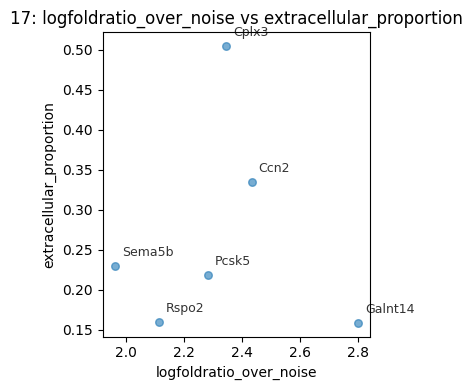

18


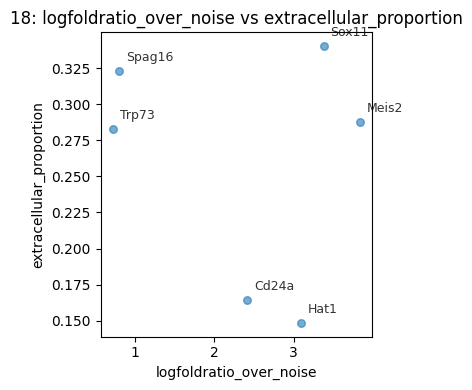

In [8]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 3].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

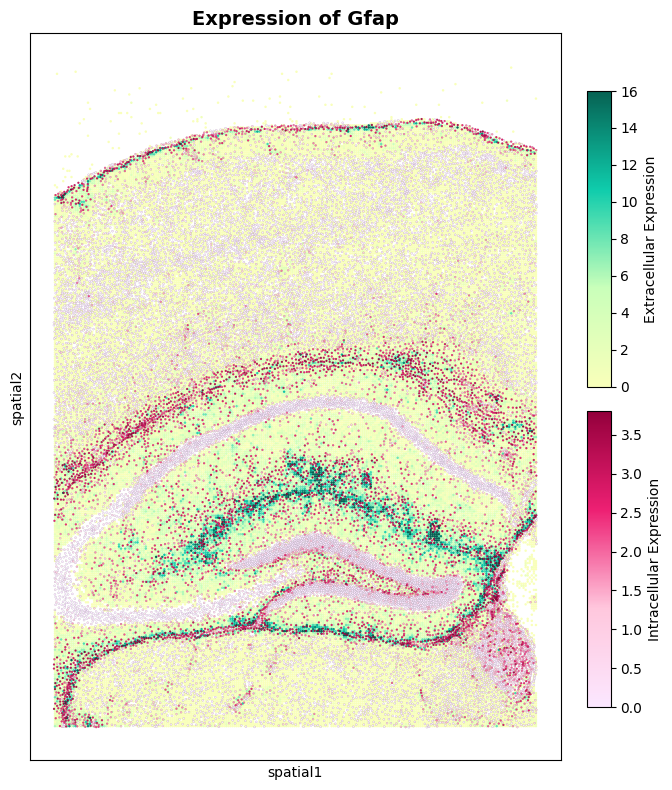

In [51]:
# spatial maps-in out
g2 = "Gfap"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

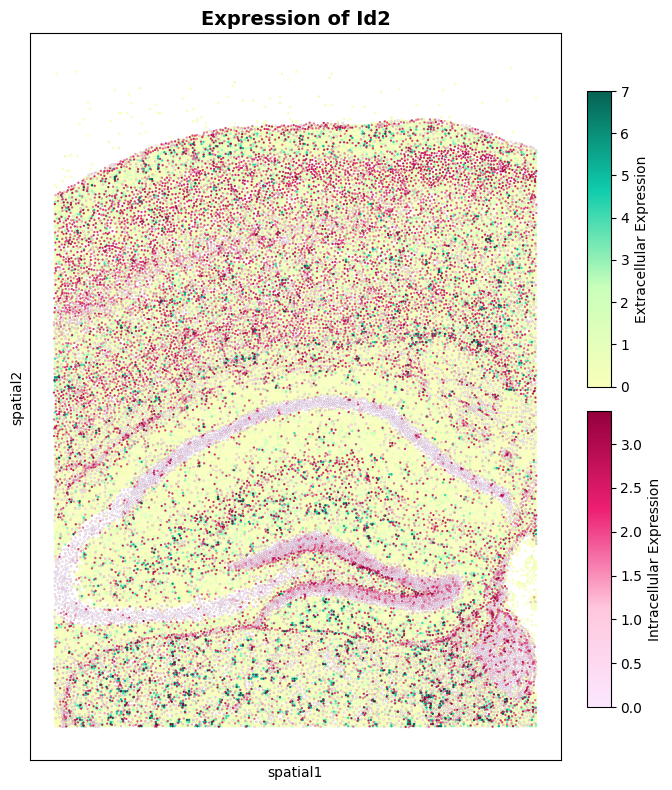

In [52]:
g2 = "Id2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

### Metrics by module

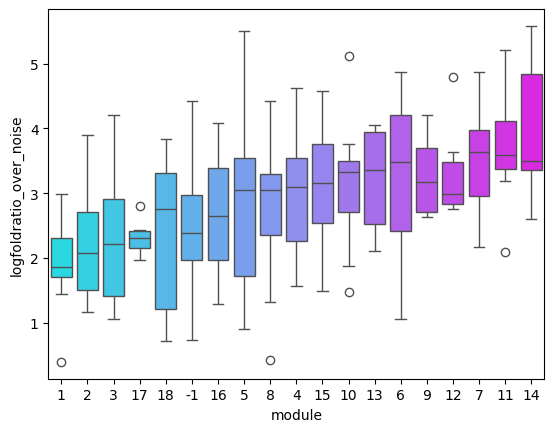

In [ ]:
import seaborn as sns
import pandas as pd

variable = "logfoldratio_over_noise"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].mean().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)

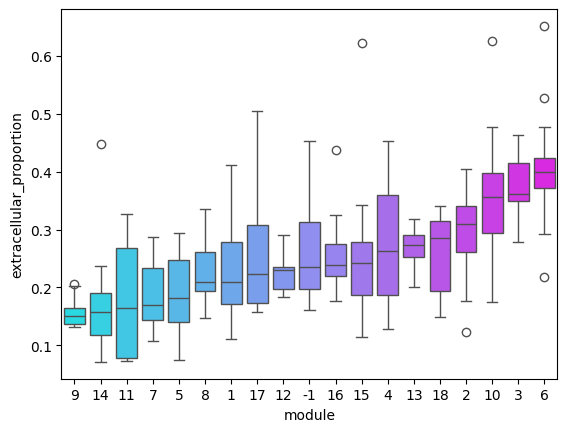

In [ ]:
import seaborn as sns
import pandas as pd

variable = "extracellular_proportion"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)

plt.title(variable)

Text(0.5, 1.0, 'moran_I')

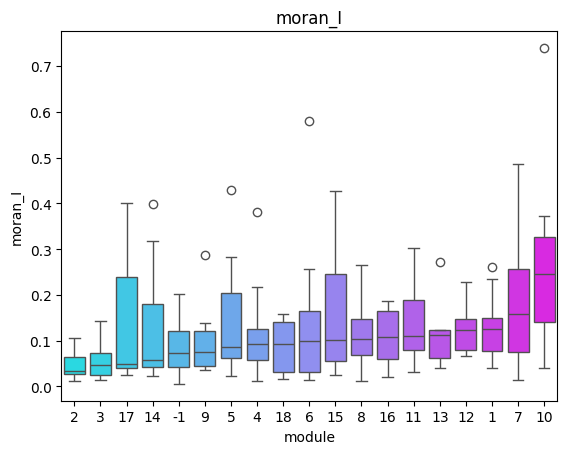

In [50]:
import seaborn as sns
import pandas as pd

variable = "moran_I"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)